In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 


files = [
    "weather.csv",
    "public_transport.csv",
    "traffic.csv",
    "power_grid.csv",
    "air_quality.csv",
    "city_events.csv",
    "districts.csv",
    "emergency_events.csv"
]

data = {}

for file in files:
    name = file.replace(".csv", "")
    data[name] = pd.read_csv(file)

# 🏙️ Smart City Analytics

![Smart City](img.png)

> **An integrated analysis of urban systems to uncover the relationships
> between mobility, environment, energy, events, and emergencies.**

---

## 📋 Table of Contents

1. [🏙️ Introduction / Project Overview](#presentation-intro)
2. [🏙️ Different Districts, Different Urban Pressures](#presentation-insight-1)
3. [🚦 Mobility Demand Drives Congestion](#presentation-insight-2)
4. [🚗 Accidents Follow Predictable Daily Patterns](#presentation-insight-3)
5. [🎉 Large Events Create Exceptional Infrastructure Demand](#presentation-insight-4)
6. [🚑 Emergency Prioritization Works](#presentation-insight-5)
7. [🚨 Weather + Traffic = Compounded Risk](#presentation-insight-6)
8. [📌 Conclusion](#presentation-conclusion)


<a id="presentation-intro"></a>


# 1. 🏙️ Project Overview

## Objective

This project analyzes interconnected urban systems to uncover meaningful
patterns and relationships across the city.

We focus on how **weather, traffic, public transportation, air quality,
energy consumption, city events, and emergency events** interact over time
and across different districts.

## Data Sources

The analysis is based on eight interconnected datasets representing:

- 🌦️ Weather
- 🚗 Traffic
- 🚌 Public Transportation
- ⚡ Power Grid
- 🌫️ Air Quality
- 🎉 City Events
- 🚨 Emergency Events
- 🏙️ District Characteristics

## Analytical Approach

We begin by understanding each system individually, then integrate related
datasets using their shared keys to investigate cross-system relationships
and uncover actionable insights.

[Next →](#presentation-insight-1)


# 2. 🗂️ Data & Schema

The datasets represent different interconnected urban systems.
The relationships between them are centered around `district_id`,
while the time-based datasets are additionally aligned by `timestamp`.

![Database Schema](erd1.png)


> **Key relationship:** Most time-based datasets use
> `district_id + timestamp` as their logical key, while `districts`
> provides the static characteristics of each district.

In [59]:
for name, df in data.items():
    print(f"{name}: {df.shape}")


weather: (526080, 13)
public_transport: (526080, 8)
traffic: (527132, 13)
power_grid: (526080, 13)
air_quality: (527132, 11)
city_events: (300, 9)
districts: (20, 15)
emergency_events: (12928, 11)


### Observation

> The datasets have different row counts, which indicates that each system
> may capture data at a different scale and requires validation before integration.

# 🧹 3. Data Preparation

In [60]:
for name, df in data.items():
    print(f"\n{name}")
    print("--------------------")
    print(df.isnull().sum())
    print()
    print("--------------------------------------")




weather
--------------------
timestamp                 0
district_id               0
temperature_c          6561
feels_like_c           6561
humidity_percent       6561
rainfall_mm            6561
wind_speed_kmh         6561
cloud_cover_percent    6561
weather_condition         0
heatwave_flag             0
heavy_rain_flag           0
storm_flag                0
sensor_status             0
dtype: int64

--------------------------------------

public_transport
--------------------
timestamp                       0
district_id                     0
passenger_count              5242
service_frequency            5242
average_delay_minutes        5242
vehicle_occupancy_percent    5242
service_disruption_flag         0
sensor_status                   0
dtype: int64

--------------------------------------

traffic
--------------------
timestamp                  0
district_id                0
traffic_volume          5265
average_speed_kmh       5265
congestion_index        5265
accident_count

Note: The equal number of missing values across several columns 
may indicate that the missing data comes from the same underlying records,
potentially reflecting periods of missing or interrupted system readings.

### Missing Values Handling

> Missing values occur in groups of measurements and coincide with a `Communication-Loss` sensor status, indicating that these values represent unavailable sensor readings rather than isolated missing observations. Therefore, the missing values will not be imputed or artificially replaced.

[Next →](#presentation-insight-1)


In [61]:
for name, df in data.items():
    print(f"\n{name}")
    print("--------------------")
    print(df.duplicated().sum())
    print()
    print("--------------------------------------")



weather
--------------------
0

--------------------------------------

public_transport
--------------------
0

--------------------------------------

traffic
--------------------
1052

--------------------------------------

power_grid
--------------------
0

--------------------------------------

air_quality
--------------------
1052

--------------------------------------

city_events
--------------------
0

--------------------------------------

districts
--------------------
0

--------------------------------------

emergency_events
--------------------
0

--------------------------------------


> **Note:** Most datasets contain no duplicate records. However, `traffic` and `air_quality` each contain 1,052 duplicate rows, indicating a potential shared duplication pattern that should be investigated before analysis.

In [62]:
data["traffic"].duplicated().sum()

np.int64(1052)

In [63]:
data["traffic"].duplicated( keep=False).sum()

np.int64(2104)

In [64]:
print (data["traffic"].duplicated().sum())
data["traffic"].duplicated( keep=False).sum()

1052


np.int64(2104)

In [65]:
data["traffic"] = data["traffic"].drop_duplicates()
data["air_quality"] = data["air_quality"].drop_duplicates()

> **Note:** Duplicate records were found in the `traffic` and `air_quality` datasets. The duplicated rows were removed while keeping one copy of each record to prevent duplicate observations from affecting the analysis.

In [66]:
for name, df in data.items():
    print(f"\n{name}")
    print("--------------------")
    print(df.duplicated().sum())
    print()
    print("--------------------------------------")



weather
--------------------
0

--------------------------------------

public_transport
--------------------
0

--------------------------------------

traffic
--------------------
0

--------------------------------------

power_grid
--------------------
0

--------------------------------------

air_quality
--------------------
0

--------------------------------------

city_events
--------------------
0

--------------------------------------

districts
--------------------
0

--------------------------------------

emergency_events
--------------------
0

--------------------------------------


In [67]:
for name, df in data.items():
    print(f"\n{name}")
    print((df.isnull().sum() / len(df) * 100).round(2))


weather
timestamp              0.00
district_id            0.00
temperature_c          1.25
feels_like_c           1.25
humidity_percent       1.25
rainfall_mm            1.25
wind_speed_kmh         1.25
cloud_cover_percent    1.25
weather_condition      0.00
heatwave_flag          0.00
heavy_rain_flag        0.00
storm_flag             0.00
sensor_status          0.00
dtype: float64

public_transport
timestamp                    0.0
district_id                  0.0
passenger_count              1.0
service_frequency            1.0
average_delay_minutes        1.0
vehicle_occupancy_percent    1.0
service_disruption_flag      0.0
sensor_status                0.0
dtype: float64

traffic
timestamp               0.0
district_id             0.0
traffic_volume          1.0
average_speed_kmh       1.0
congestion_index        1.0
accident_count          1.0
accident_flag           0.0
road_incident_count     1.0
rush_hour_flag          1.0
weekend_flag            1.0
weather_impact_score    1.

> **Note:** Missing values are limited to approximately 1–1.25% of the operational measurements. They are concentrated in numerical sensor readings, while identifiers and event-based datasets are complete.

#🔍 Exploratory Analysis

## 🏙️ Smart City Pulse

Before looking at weather, traffic, energy, or emergencies, we first need to understand how the city is structured.

Each district has different characteristics in terms of population, density, economic activity, infrastructure, and public services.

This gives us the context needed to interpret the patterns we will discover later.


In [68]:
data["districts"].describe()

,area_km2,population,commercial_activity_index,industrial_activity_index,green_space_percent,road_capacity_index,public_transport_access_index,base_electricity_demand_mwh,temp_offset_c,wind_multiplier,population_density,grid_capacity_mwh
count,20.0000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000
mean,9.8250,67300.000000,56.000000,19.750000,24.500000,66.500000,70.000000,329.000000,0.240000,0.995000,8267.382641,522.124402
std,6.2476,58560.899475,26.881808,29.579287,21.139885,17.851729,18.353259,199.417573,0.916745,0.258488,6383.611536,336.607098
min,3.0000,1000.000000,15.000000,0.000000,2.000000,30.000000,30.000000,50.000000,-1.500000,0.500000,117.647059,82.905533
25%,5.1500,15000.000000,33.750000,5.000000,10.000000,55.000000,60.000000,187.500000,-0.500000,0.875000,2576.923077,289.012582
50%,8.0000,52500.000000,57.500000,10.000000,20.000000,67.500000,75.000000,240.000000,0.200000,1.000000,8333.333333,371.193614
75%,12.8750,112500.000000,77.500000,16.250000,30.000000,80.000000,85.000000,412.500000,1.000000,1.125000,13191.699605,650.576713
max,25.0000,180000.000000,100.000000,100.000000,90.000000,100.000000,95.000000,800.000000,2.000000,1.500000,23076.923077,1306.398788


<a id="presentation-insight-1"></a>


## 🏙️ Where Does the City Actually Live?


In [69]:
data["districts"][["district_name", "population"]].sort_values(
    "population",
    ascending=False
)

,district_name,population
3,North Residential,180000
4,South Residential,160000
6,West Residential,150000
5,East Residential,140000
0,Downtown,120000
19,Suburban District,110000
18,Hillside,90000
8,University District,85000
17,Riverside,75000
10,Old Town,60000


In [70]:
df=data["districts"]
df[ "population_share"]=df["population"]/df["population"].sum()
df[["district_name",  "population_share"]].sort_values("population_share", ascending=False)

,district_name,population_share
3,North Residential,0.133730
4,South Residential,0.118871
6,West Residential,0.111441
5,East Residential,0.104012
0,Downtown,0.089153
19,Suburban District,0.081724
18,Hillside,0.066865
8,University District,0.063150
17,Riverside,0.055721
10,Old Town,0.044577


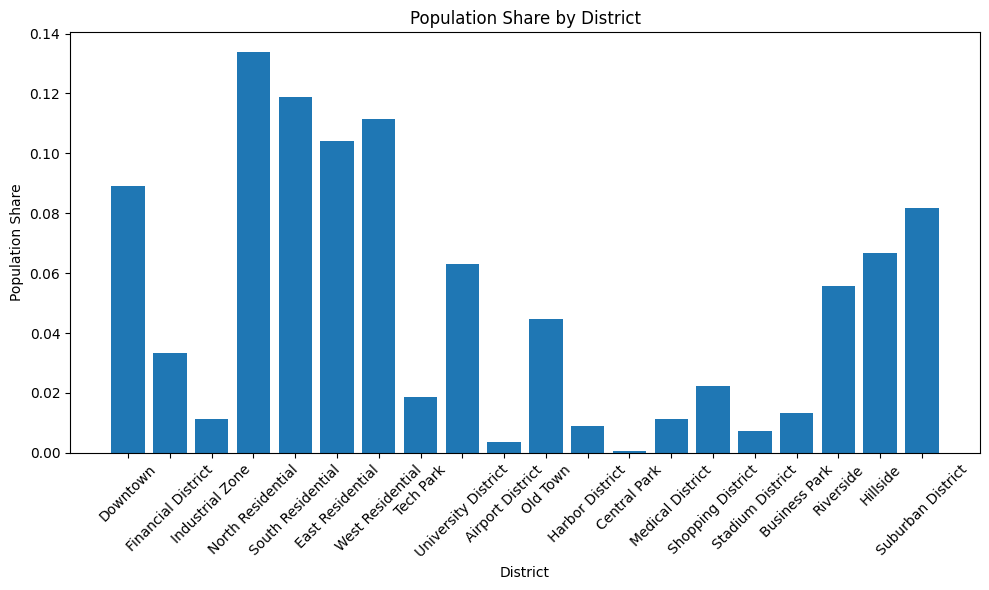

In [71]:
plt.figure(figsize=(10, 6))
plt.bar(df["district_name"], df["population_share"])
plt.xticks(rotation=45)
plt.title("Population Share by District")
plt.xlabel("District")
plt.ylabel("Population Share")
plt.tight_layout()
plt.show()

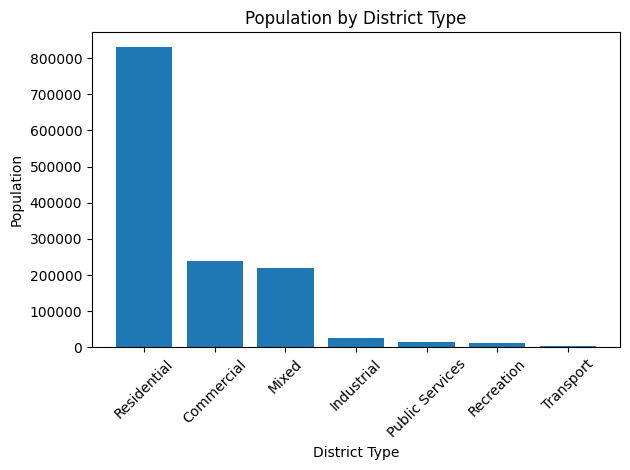

In [72]:
d_type= data["districts"].groupby("district_type")["population"].sum().sort_values(ascending=False)
plt.bar(d_type.index, d_type.values)
plt.xticks(rotation=45)
plt.title("Population by District Type")
plt.xlabel("District Type")
plt.ylabel("Population")
plt.tight_layout()
plt.show()

The city's population is predominantly concentrated in Residential districts,
 while Commercial and Mixed districts form the next largest population groups.

In [73]:
data["districts"].groupby("district_type")["commercial_activity_index"].mean().sort_values(ascending=False)

district_type
Commercial         91.000000
Transport          70.000000
Mixed              63.333333
Public Services    60.000000
Recreation         42.500000
Industrial         40.000000
Residential        30.000000
Name: commercial_activity_index, dtype: float64

### 💡 Insight

The city's population is mainly concentrated in Residential districts, while Commercial districts have the highest average commercial activity.

This shows that the areas where most people live are not necessarily the same areas where most commercial activity is concentrated.

[← Previous](#presentation-intro) | [Next →](#presentation-insight-2)


## ⚡ Does Grid Capacity Keep Pace With Electricity Demand Across District Types?

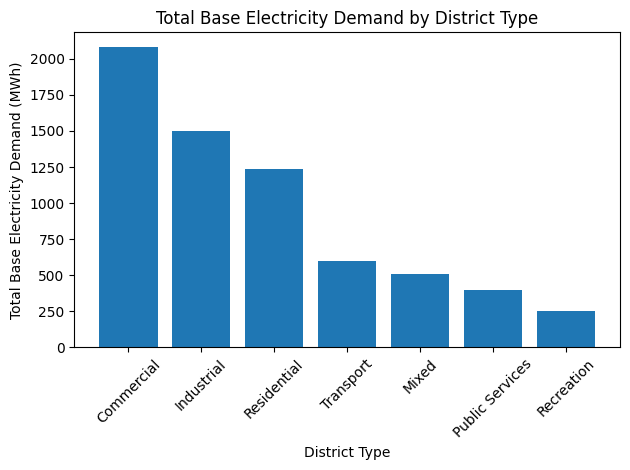

In [74]:

g_c=df.groupby("district_type")["base_electricity_demand_mwh"].sum().sort_values(ascending=False)
plt.bar(g_c.index, g_c.values)
plt.xlabel("District Type")
plt.ylabel("Total Base Electricity Demand (MWh)")
plt.title("Total Base Electricity Demand by District Type")
plt.xticks(rotation=45)
plt.tight_layout()

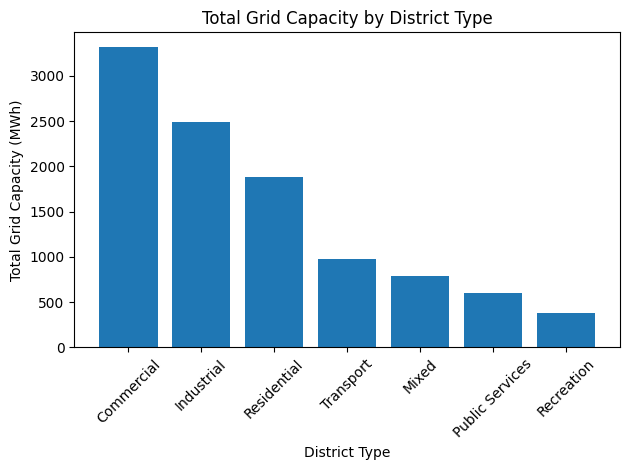

In [75]:

g_c=df.groupby("district_type")["grid_capacity_mwh"].sum().sort_values(ascending=False)
plt.bar(g_c.index, g_c.values)
plt.xlabel("District Type")
plt.ylabel("Total Grid Capacity (MWh)")
plt.title("Total Grid Capacity by District Type")
plt.xticks(rotation=45)
plt.tight_layout()

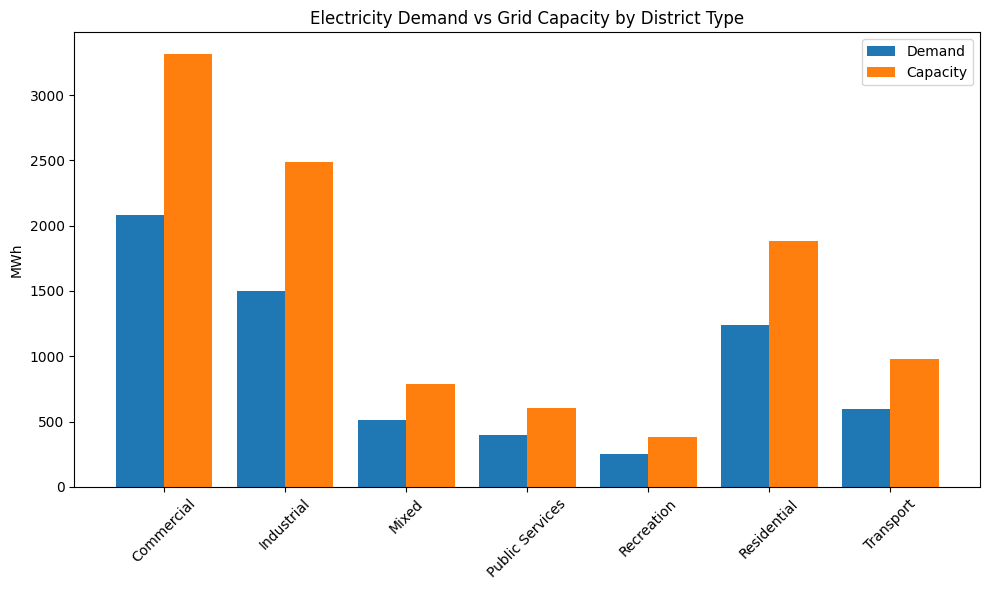

In [76]:
grouped = df.groupby("district_type")[
    ["base_electricity_demand_mwh", "grid_capacity_mwh"]
].sum()

x = range(len(grouped))

plt.figure(figsize=(10, 6))

plt.bar([i - 0.2 for i in x], grouped["base_electricity_demand_mwh"], width=0.4, label="Demand")
plt.bar([i + 0.2 for i in x], grouped["grid_capacity_mwh"], width=0.4, label="Capacity")

plt.xticks(x, grouped.index, rotation=45)
plt.ylabel("MWh")
plt.title("Electricity Demand vs Grid Capacity by District Type")
plt.legend()

plt.tight_layout()
plt.show()

### 💡 Insight

Grid capacity exceeds base electricity demand across all district types, indicating that the city's grid has spare capacity relative to baseline demand.

Commercial districts show the highest electricity demand and the largest grid capacity, followed by Industrial and Residential districts.

## 🌳 Which District Types Have the Most and Least Green Space?

In [77]:
green_type = df.groupby("district_type")["green_space_percent"].mean().sort_values(ascending=False)

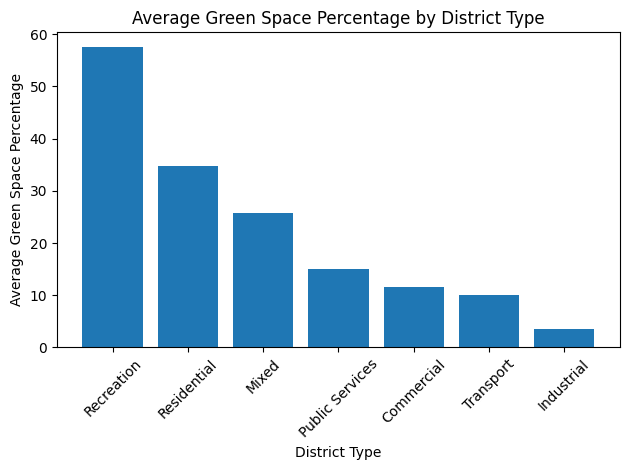

In [78]:
plt.bar(green_type.index, green_type.values)
plt.xticks(rotation=45)
plt.title("Average Green Space Percentage by District Type")
plt.xlabel("District Type")
plt.ylabel("Average Green Space Percentage")
plt.tight_layout()

### 💡 Insight

Recreational districts have the highest average green-space coverage, followed by Residential and Mixed districts.

In contrast, Industrial districts have by far the lowest green-space coverage, while Commercial and Transport districts also have relatively limited green space.


<a id="presentation-insight-3"></a>


# 🔗 Connecting the City's Systems: Traffic, Mobility, Events, and Urban Pressure

## 🔗 Connecting the City's Systems: 


In [79]:
traffic_city = df.merge(
    data["traffic"],
    on="district_id"
)

In [80]:
traffic_city.groupby("district_name")["accident_count"].sum()

district_name
Airport District        716.0
Business Park           931.0
Central Park            655.0
Downtown               1073.0
East Residential        971.0
Financial District      959.0
Harbor District         716.0
Hillside                862.0
Industrial Zone         654.0
Medical District        813.0
North Residential      1149.0
Old Town               1536.0
Riverside               977.0
Shopping District       979.0
South Residential      1039.0
Stadium District        727.0
Suburban District       836.0
Tech Park               863.0
University District    1119.0
West Residential       1102.0
Name: accident_count, dtype: float64

In [81]:
district_accidents = traffic_city.groupby(
    ["district_id", "district_name", "population"]
)["accident_count"].sum()

district_accidents

district_id  district_name        population
D01          Downtown             120000        1073.0
D02          Financial District   45000          959.0
D03          Industrial Zone      15000          654.0
D04          North Residential    180000        1149.0
D05          South Residential    160000        1039.0
D06          East Residential     140000         971.0
D07          West Residential     150000        1102.0
D08          Tech Park            25000          863.0
D09          University District  85000         1119.0
D10          Airport District     5000           716.0
D11          Old Town             60000         1536.0
D12          Harbor District      12000          716.0
D13          Central Park         1000           655.0
D14          Medical District     15000          813.0
D15          Shopping District    30000          979.0
D16          Stadium District     10000          727.0
D17          Business Park        18000          931.0
D18          Riversi

In [82]:
df = data ["traffic" ].merge(
   data ["public_transport"],
    on=["timestamp", "district_id"],
    how="inner"
)
df[[
    "passenger_count",
    "traffic_volume",
    "average_speed_kmh",
    "congestion_index"
]].corr()

,passenger_count,traffic_volume,average_speed_kmh,congestion_index
passenger_count,1.000000,0.739293,-0.688407,0.730551
traffic_volume,0.739293,1.000000,-0.824235,0.875719
average_speed_kmh,-0.688407,-0.824235,1.000000,-0.963199
congestion_index,0.730551,0.875719,-0.963199,1.000000


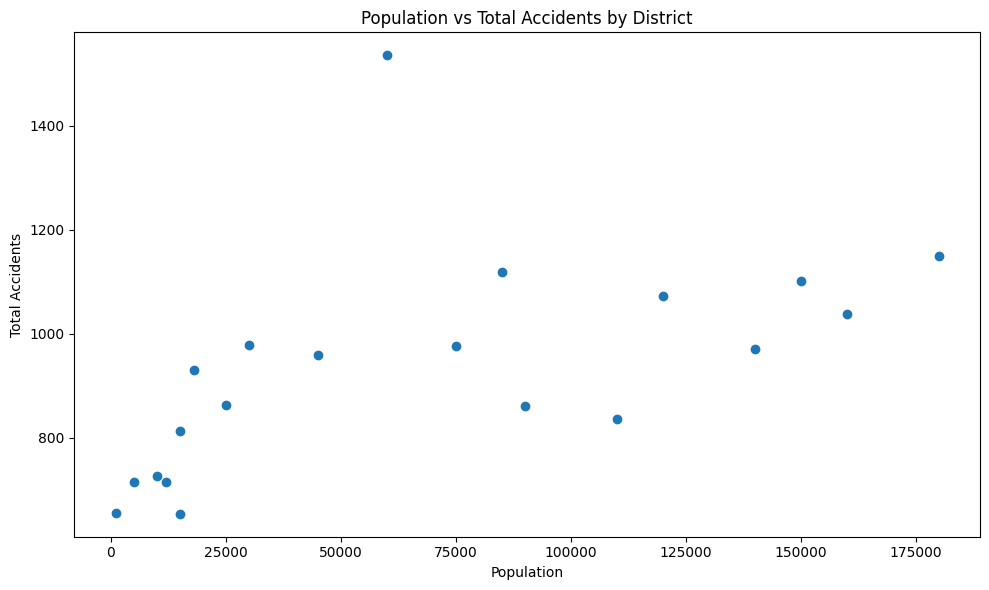

In [83]:
plt.figure(figsize=(10, 6))

plt.scatter(
    district_accidents.index.get_level_values("population"),
    district_accidents.values
)

plt.xlabel("Population")
plt.ylabel("Total Accidents")
plt.title("Population vs Total Accidents by District")

plt.tight_layout()
plt.show()

### 💡 Insight

Districts with larger populations generally tend to experience more accidents, but the relationship is not proportional.

Some less-populated districts record unusually high accident levels, suggesting that factors beyond population may contribute to traffic risk.

In [84]:
traffic_accidents = traffic_city.groupby("district_name")[
    ["traffic_volume", "accident_count"]
].mean().sort_values("traffic_volume", ascending=False)


In [85]:
traffic_accidents

,traffic_volume,accident_count
district_name,,
Downtown,2489.342762,0.041236
Financial District,2057.785525,0.036821
North Residential,1945.859062,0.044101
West Residential,1828.391171,0.042303
Shopping District,1776.781904,0.037597
South Residential,1723.528511,0.039896
Old Town,1723.262274,0.059009
Tech Park,1655.106205,0.033136
University District,1636.395669,0.042961


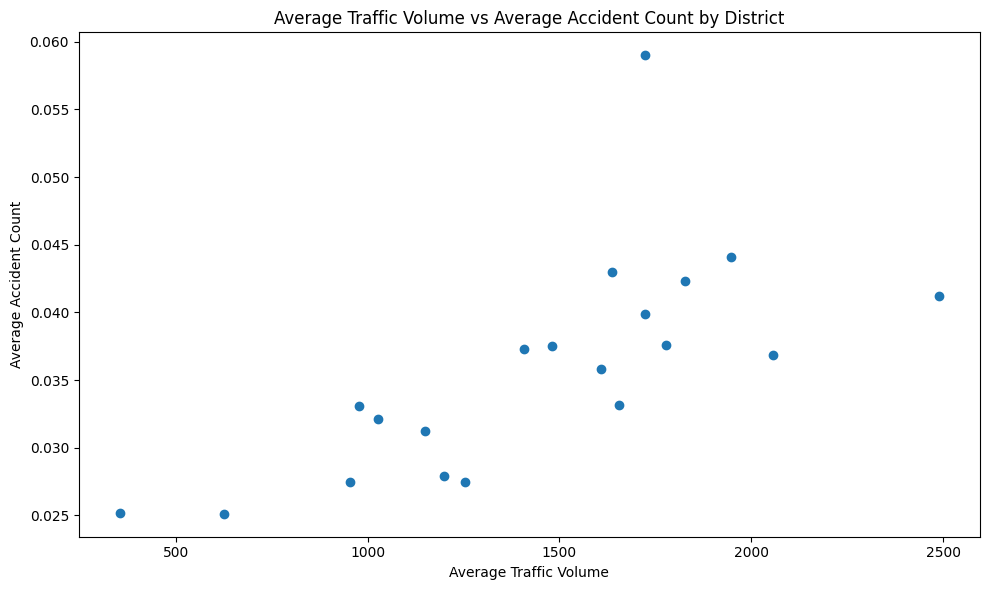

In [86]:
plt.figure(figsize=(10, 6))
plt.scatter(traffic_accidents["traffic_volume"], traffic_accidents["accident_count"])
plt.xlabel("Average Traffic Volume")
plt.ylabel("Average Accident Count")
plt.title("Average Traffic Volume vs Average Accident Count by District")   
plt.tight_layout()
plt.show()

### 💡 Insight

Districts with higher average traffic volumes generally tend to experience more accidents. However, the relationship is not perfectly proportional, suggesting that other factors also contribute to traffic risk.

Text(0.5, 1.0, 'Average Road Capacity Index vs Average Accident Count by District')

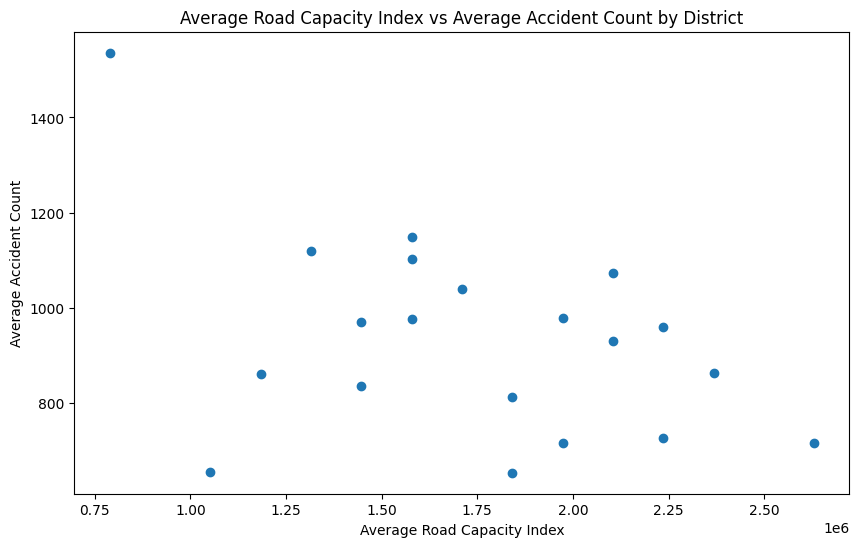

In [87]:
road_accidents = traffic_city.groupby("district_name")[
    ["road_capacity_index", "accident_count"]
].sum().sort_values("road_capacity_index", ascending=False)

plt.figure(figsize=(10, 6))
plt.scatter(road_accidents["road_capacity_index"], road_accidents["accident_count"])
plt.xlabel("Average Road Capacity Index")
plt.ylabel("Average Accident Count")
plt.title("Average Road Capacity Index vs Average Accident Count by District")

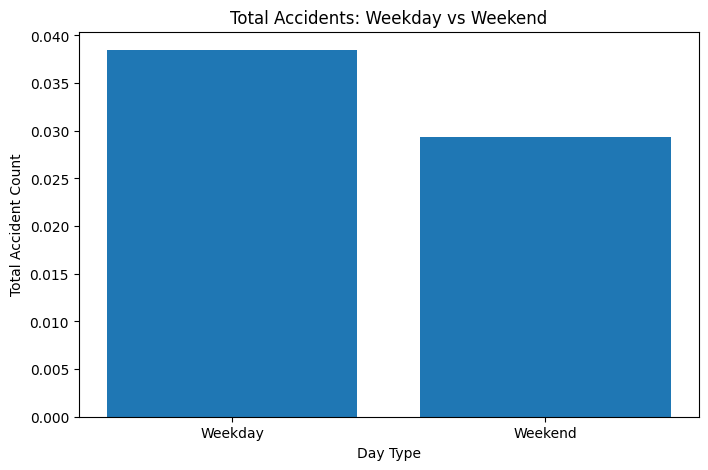

In [88]:
accidents_weekend = (
    traffic_city
    .groupby("weekend_flag")["accident_count"]
    .mean()
)

plt.figure(figsize=(8, 5))
plt.bar(
    ["Weekday", "Weekend"],
    accidents_weekend.values
)

plt.xlabel("Day Type")
plt.ylabel("Total Accident Count")
plt.title("Total Accidents: Weekday vs Weekend")
plt.show()

### 📌 Insight: Weekday vs Weekend Accidents

- The **average accident count is higher on weekdays (~0.038)** compared to weekends (~0.029).
- This suggests that **accidents are more frequent on weekdays than weekends** in the analyzed data.
- The difference is around **23% lower on weekends** compared with weekdays.

> **Conclusion:** Weekdays show a higher average accident count than weekends, indicating a potential relationship between day type and accident frequency.

## 🚦 Rush Hour vs Accident Count

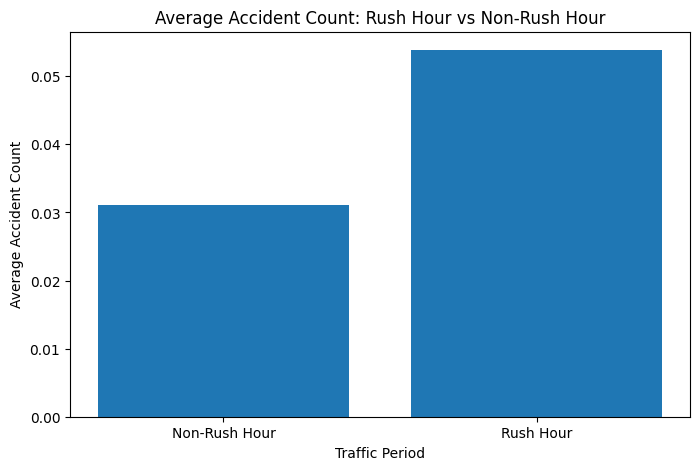

In [89]:
accidents_rush = (
    traffic_city
    .groupby("rush_hour_flag")["accident_count"]
    .mean()
)

plt.figure(figsize=(8, 5))

plt.bar(
    ["Non-Rush Hour", "Rush Hour"],
    accidents_rush.values
)

plt.xlabel("Traffic Period")
plt.ylabel("Average Accident Count")
plt.title("Average Accident Count: Rush Hour vs Non-Rush Hour")

plt.show()

### 🚦 Insight: Rush Hour vs Accident Count

- The average accident count during **Rush Hours (~0.054)** is substantially higher than during **Non-Rush Hours (~0.031)**.
- This represents approximately a **74% higher average accident count during Rush Hours**.
- This suggests a strong association between **peak traffic periods and higher accident frequency**.

> **Conclusion:** Rush Hours are associated with a noticeably higher average number of accidents, highlighting peak traffic periods as a potential high-risk period for road safety.

In [90]:
event_impact_congestion = (
    data["traffic"]
    .groupby("special_event_impact")["congestion_index"]
    .mean()
    .sort_index()
)

event_impact_congestion

special_event_impact
0.0    28.968594
1.1    40.040523
1.3    45.067806
1.8    60.702520
2.5    83.441331
Name: congestion_index, dtype: float64

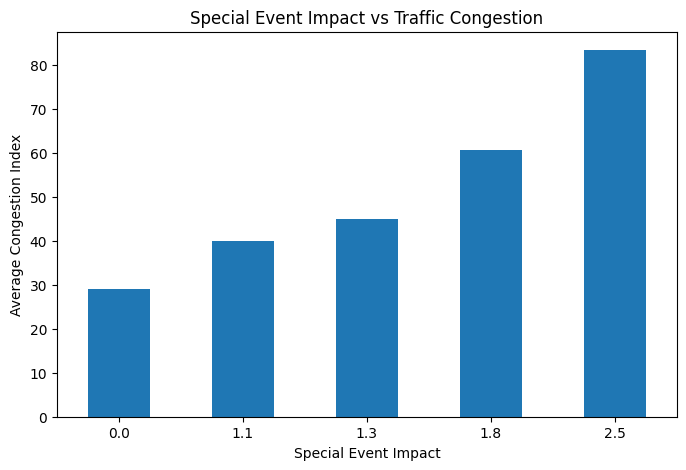

In [91]:
plt.figure(figsize=(8, 5))

event_impact_congestion.plot(kind="bar")

plt.xlabel("Special Event Impact")
plt.ylabel("Average Congestion Index")
plt.title("Special Event Impact vs Traffic Congestion")
plt.xticks(rotation=0)

plt.show()

### 💡 Insight

Higher special event impact is consistently associated with higher average traffic congestion. This indicates that major events can place significant pressure on the city's road network.

[← Previous](#presentation-insight-2) | [Next →](#presentation-insight-4)


<a id="presentation-insight-2"></a>


## Public Transport & Traffic Analysis

## Public Transport Demand vs Traffic Congestion

The correlation analysis shows a positive relationship between public transport demand and traffic congestion.

- Passenger count and congestion index: **r = 0.73**
- Passenger count and traffic volume: **r = 0.74**
- Passenger count and average speed: **r = -0.69**

This suggests that higher public transport demand is associated with higher traffic pressure and lower average traffic speed.

> **Note:** Correlation indicates association, not causation.

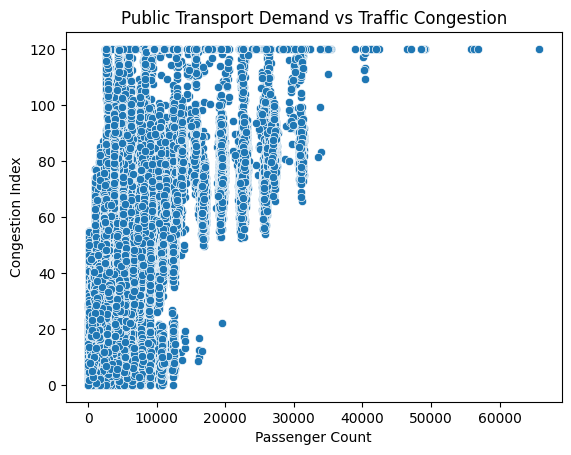

In [92]:
import seaborn as sns

sns.scatterplot(
    data=df,
    x="passenger_count",
    y="congestion_index"
)

plt.title("Public Transport Demand vs Traffic Congestion")
plt.xlabel("Passenger Count")
plt.ylabel("Congestion Index")
plt.show()

### Business Insight

Higher public transport demand is strongly associated with increased traffic pressure. Passenger count shows a positive correlation with both traffic volume (**r = 0.74**) and congestion (**r = 0.73**), while average speed decreases as passenger demand increases (**r = -0.69**).

This suggests that periods of high transport demand coincide with heavier traffic and slower movement across the city.

> **Business implication:** High-demand periods may require better coordination between public transport capacity and traffic management to maintain mobility and reduce congestion.

[← Previous](#presentation-insight-1) | [Next →](#presentation-insight-3)


## Weather Impact on Traffic and Accidents

The analysis examines whether weather conditions are associated with changes in traffic congestion, average speed, and accident rates.

Key weather factors include:
- Rainfall
- Wind speed
- Temperature
- Heavy rain
- Storms
- Heatwaves

These factors will be compared with traffic and accident indicators to identify meaningful patterns and potential operational risks.

In [93]:
weather_traffic = data["weather"].merge(
    data["traffic"],
    on=["timestamp", "district_id"],
    how="inner"
)

In [94]:
weather_traffic[[
    "rainfall_mm",
    "wind_speed_kmh",
    "temperature_c",
    "congestion_index",
    "average_speed_kmh",
    "accident_count"
]].corr()

,rainfall_mm,wind_speed_kmh,temperature_c,congestion_index,average_speed_kmh,accident_count
rainfall_mm,1.000000,0.415500,0.005244,0.097339,-0.225307,0.085060
wind_speed_kmh,0.415500,1.000000,-0.014434,0.004169,-0.127788,0.080026
temperature_c,0.005244,-0.014434,1.000000,0.150288,-0.143903,0.010317
congestion_index,0.097339,0.004169,0.150288,1.000000,-0.963199,0.094964
average_speed_kmh,-0.225307,-0.127788,-0.143903,-0.963199,1.000000,-0.115009
accident_count,0.085060,0.080026,0.010317,0.094964,-0.115009,1.000000


### Business Insight

Weather conditions show limited linear association with traffic congestion and accidents.

Rainfall has a weak relationship with congestion (r = 0.10) and accident count (r = 0.09), while wind speed and temperature show almost no correlation with accidents.

This suggests that weather-related conditions are not major drivers of traffic congestion or accidents in the observed data.

> **Business implication:** Traffic management efforts should prioritize stronger operational drivers rather than relying primarily on weather conditions.

In [95]:
air_traffic = data["air_quality"].merge(
    data["traffic"],
    on=["timestamp", "district_id"],
    how="inner"
)

In [96]:
data["air_quality"]

,timestamp,district_id,pm25,pm10,no2,o3,co,synthetic_aqi,air_quality_category,pollution_alert_flag,sensor_status
0,2024-05-01 22:00:00,D11,13.845142,29.216811,22.758277,22.128768,1.341131,34.0,Good,0,Normal
1,2023-11-21 06:00:00,D08,23.617775,34.630069,31.060166,21.560664,1.066556,59.0,Moderate,0,Normal
2,2024-09-02 10:00:00,D02,15.465175,27.307933,28.727307,78.610070,1.123513,78.0,Moderate,0,Normal
3,2025-03-14 23:00:00,D09,4.054570,5.819488,9.511867,0.269460,0.569737,11.0,Good,0,Normal
4,2024-09-10 07:00:00,D14,29.953995,47.001299,44.735950,44.779858,1.587633,74.0,Moderate,0,Normal
...,...,...,...,...,...,...,...,...,...,...,...
527127,2023-01-16 09:00:00,D17,8.880395,17.091528,14.511241,27.730812,1.017884,27.0,Good,0,Normal
527128,2023-09-03 16:00:00,D18,14.708616,26.131330,21.595183,55.328278,0.718461,55.0,Moderate,0,Normal
527129,2023-01-31 12:00:00,D10,29.451436,52.058873,33.247696,39.081503,0.621691,73.0,Moderate,0,Normal
527130,2023-08-22 17:00:00,D12,53.340108,85.719320,54.080943,43.769245,0.860015,133.0,Unhealthy for Sensitive Groups,0,Normal


In [97]:
air_traffic[[
    "pm25",
    "pm10",
    "no2",
    "o3",
    "co",
    "synthetic_aqi",
    "congestion_index",
    "average_speed_kmh",
    "accident_count"
]].corr()

,pm25,pm10,no2,o3,co,synthetic_aqi,congestion_index,average_speed_kmh,accident_count
pm25,1.000000,0.987882,0.905977,0.213514,0.309051,0.926427,0.079090,-0.051469,-0.007473
pm10,0.987882,1.000000,0.894949,0.210601,0.305236,0.915077,0.077813,-0.050520,-0.007658
no2,0.905977,0.894949,1.000000,0.276626,0.557652,0.847499,0.291667,-0.249532,0.006872
o3,0.213514,0.210601,0.276626,1.000000,0.279231,0.465517,0.216379,-0.172002,-0.004547
co,0.309051,0.305236,0.557652,0.279231,1.000000,0.280148,0.694705,-0.639476,0.042195
synthetic_aqi,0.926427,0.915077,0.847499,0.465517,0.280148,1.000000,0.080995,-0.049023,-0.009574
congestion_index,0.079090,0.077813,0.291667,0.216379,0.694705,0.080995,1.000000,-0.963199,0.094964
average_speed_kmh,-0.051469,-0.050520,-0.249532,-0.172002,-0.639476,-0.049023,-0.963199,1.000000,-0.115009
accident_count,-0.007473,-0.007658,0.006872,-0.004547,0.042195,-0.009574,0.094964,-0.115009,1.000000


### Business Insight

Carbon monoxide (CO) shows the strongest relationship with traffic conditions among the measured air pollutants.

CO is positively associated with traffic congestion (r = 0.69) and negatively associated with average speed (r = -0.64), while NO₂ shows a weaker positive relationship with congestion (r = 0.29).

This suggests that areas or periods with heavier traffic tend to coincide with higher CO levels and lower traffic speeds.

> **Business implication:** Traffic management can also support air-quality objectives, particularly by reducing prolonged congestion and improving traffic flow.

> **Note:** These correlations indicate association, not causation.

In [98]:
data["power_grid"]["load_ratio"] = (
    data["power_grid"]["electricity_demand_mwh"] /
    data["power_grid"]["grid_capacity_mwh"]
)

data["power_grid"]["load_ratio"].describe()

count    520604.000000
mean          0.615916
std           0.174072
min           0.289586
25%           0.478357
50%           0.628496
75%           0.743866
max           1.970718
Name: load_ratio, dtype: float64

### Key Insight

The power grid operates at an average **load ratio of 61.6%**, indicating that electricity demand generally uses a moderate portion of the available grid capacity. However, the **maximum load ratio reaches 197.1%**, showing that some periods experience demand exceeding the available capacity.

This indicates potential **grid capacity stress during peak-demand periods**, highlighting the need for capacity planning and peak-load management to reduce the risk of overloads and maintain grid reliability.

<a id="presentation-insight-4"></a>


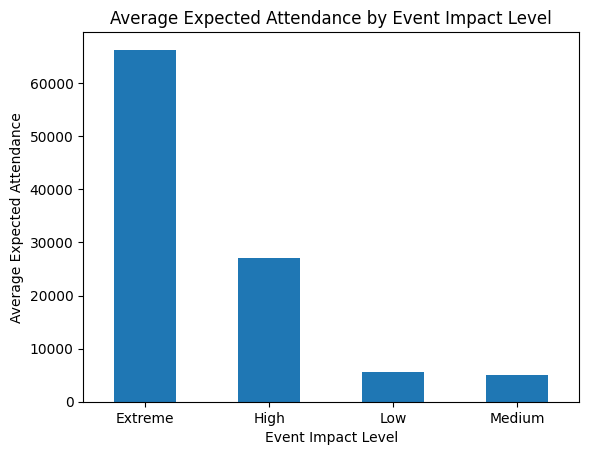

In [99]:
event_impact = (
    data["city_events"]
    .groupby("event_impact_level")["expected_attendance"]
    .mean()
    .sort_values(ascending=False)
)

event_impact.plot(kind="bar")

plt.title("Average Expected Attendance by Event Impact Level")
plt.xlabel("Event Impact Level")
plt.ylabel("Average Expected Attendance")
plt.xticks(rotation=0)
plt.show()

### Key Insight

Event impact level is strongly associated with expected attendance. **Extreme-impact events attract the highest expected attendance**, averaging around **66,000 attendees**, followed by **High-impact events** at approximately **27,000**.

In contrast, **Low and Medium-impact events** have much lower expected attendance, at around **5,000–6,000 attendees**.

This indicates that **higher-impact events are likely to create significantly greater demand on city infrastructure and public services**, requiring stronger transportation, security, and emergency-response planning.

[← Previous](#presentation-insight-3) | [Next →](#presentation-insight-5)


<a id="presentation-insight-5"></a>


## Emergency Events Analysis

Emergency events were analyzed to evaluate response performance across different emergency types, severity levels, and districts.

In [100]:
response_by_type = (
    data["emergency_events"]
    .groupby("emergency_type")["response_time_minutes"]
    .mean()
    .sort_values(ascending=False)
)

response_by_type

emergency_type
Weather Emergency         33.669758
Infrastructure Failure    24.585286
Traffic Accident          21.478974
Fire                      20.866173
Public Safety Incident    20.658059
Medical Emergency         20.430276
Name: response_time_minutes, dtype: float64

### Key Insight

Event impact level is strongly associated with expected attendance. **Extreme-impact events attract the highest expected attendance**, averaging around **66,000 attendees**, followed by **High-impact events** at approximately **27,000**.

In contrast, **Low and Medium-impact events** have much lower expected attendance, at around **5,000–6,000 attendees**.

This indicates that **higher-impact events are likely to create significantly greater demand on city infrastructure and public services**, requiring stronger transportation, security, and emergency-response planning.

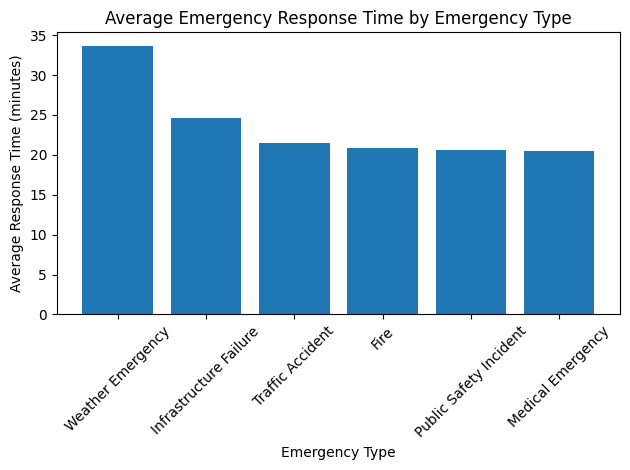

In [101]:
plt.bar(response_by_type.index, response_by_type.values)
plt.title("Average Emergency Response Time by Emergency Type")
plt.xlabel("Emergency Type")
plt.ylabel("Average Response Time (minutes)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Key Insight

Response performance varies significantly by emergency type. **Weather Emergencies have the longest average response time at 33.7 minutes**, followed by **Infrastructure Failures at 24.6 minutes**.

In contrast, **Medical Emergencies have the fastest average response time at 20.4 minutes**, with Fire, Public Safety Incidents, and Traffic Accidents falling between these extremes.

This suggests that **weather-related and infrastructure emergencies may require additional response capacity and preparedness**, as they currently experience longer response times than other emergency types.

In [102]:
emergency_district = data["emergency_events"].merge(
    data["districts"],
    on="district_id",
    how="left"
)

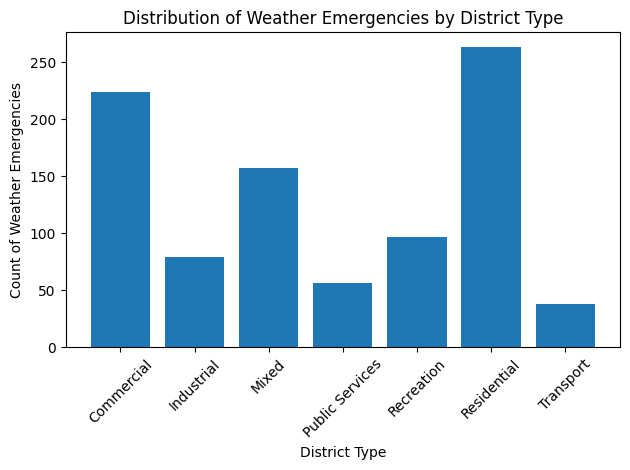

In [103]:
weather_emergency = emergency_district[
    emergency_district["emergency_type"] == "Weather Emergency"
]

weather_emergency=weather_emergency.groupby("district_type")["emergency_type"].count()
plt.bar(weather_emergency.index, weather_emergency.values)
plt.title("Distribution of Weather Emergencies by District Type")
plt.xlabel("District Type")
plt.ylabel("Count of Weather Emergencies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Key Insight

Weather emergencies are **not evenly distributed across district types**. **Residential districts experience the highest number of weather emergencies**, followed by **Commercial and Mixed-use districts**.

In contrast, **Transport and Public Services districts record the fewest incidents**.

This indicates that **residential and commercially active areas may require greater weather preparedness and emergency-response capacity**, helping the city prioritize resources where weather-related incidents are most frequent.

In [104]:
emergency_weather = data["emergency_events"].merge(
    data["weather"],
    on=["district_id", "timestamp"],
    how="left"
)
emergency_weather_traffic = emergency_weather.merge(
    data["traffic"],
    on=["district_id", "timestamp"],
    how="left"
)
emergency_weather_traffic.groupby(
    "weather_condition"
)["response_time_minutes"].mean().sort_values(ascending=False)
emergency_weather_traffic.groupby(
    "traffic_volume"
)["response_time_minutes"].mean().sort_values(ascending=False)
a=emergency_weather_traffic.groupby(
    ["weather_condition", "traffic_volume"]
)["response_time_minutes"].mean()

In [105]:
# Create traffic levels
emergency_weather_traffic["traffic_level"] = pd.qcut(
    emergency_weather_traffic["traffic_volume"],
    q=3,
    labels=["Low", "Medium", "High"]
)

# Calculate average response time
weather_traffic_response = (
    emergency_weather_traffic
    .groupby(["weather_condition", "traffic_level"], observed=True)["response_time_minutes"]
    .mean()
    .unstack()
)

weather_traffic_response

traffic_level,Low,Medium,High
weather_condition,,,
Clear,12.321597,18.679996,22.377957
Cloudy,13.445280,NaN,NaN
Heatwave,14.880539,13.363820,20.869618
Partly Cloudy,14.364069,17.292526,22.431607
Rain,10.050148,23.246932,23.984701
Storm,28.153953,36.306607,42.620245


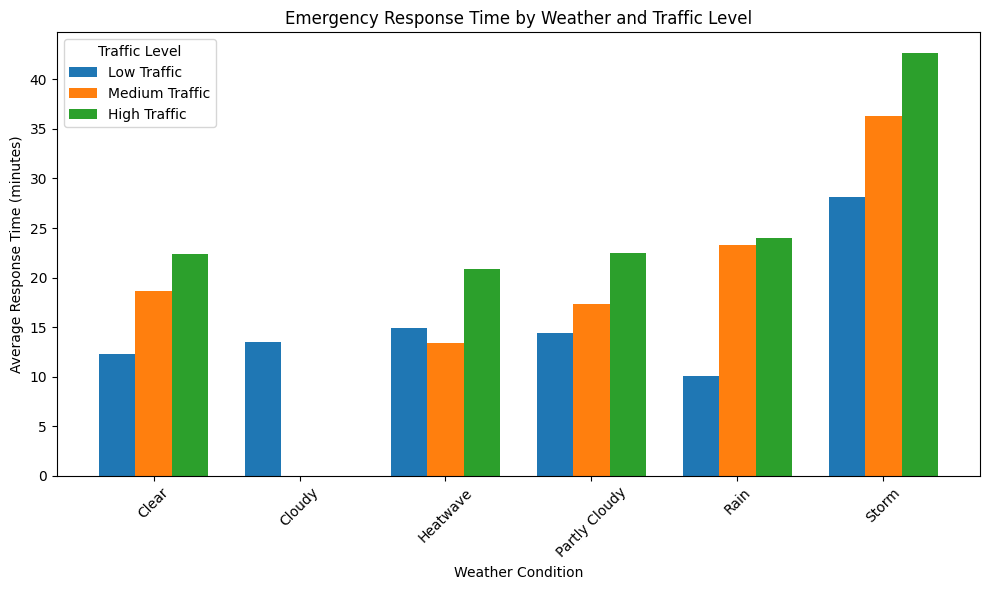

In [106]:
plt.figure(figsize=(10, 6))

x = range(len(weather_traffic_response))
width = 0.25

plt.bar(
    [i - width for i in x],
    weather_traffic_response["Low"],
    width=width,
    label="Low Traffic"
)

plt.bar(
    x,
    weather_traffic_response["Medium"],
    width=width,
    label="Medium Traffic"
)

plt.bar(
    [i + width for i in x],
    weather_traffic_response["High"],
    width=width,
    label="High Traffic"
)

plt.xticks(x, weather_traffic_response.index, rotation=45)
plt.xlabel("Weather Condition")
plt.ylabel("Average Response Time (minutes)")
plt.title("Emergency Response Time by Weather and Traffic Level")
plt.legend(title="Traffic Level")
plt.tight_layout()
plt.show()

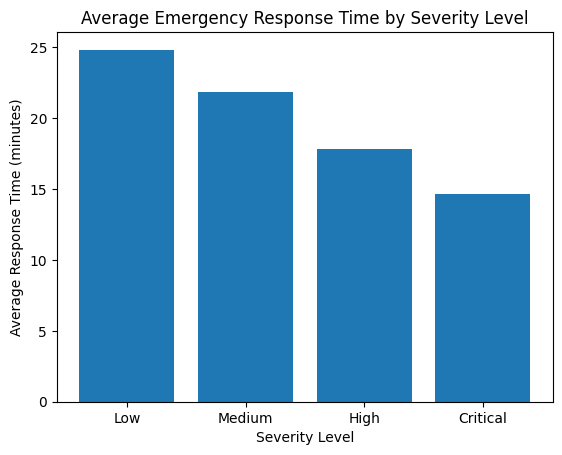

In [107]:
response_by_severity = (
    data["emergency_events"]
    .groupby("severity_level")["response_time_minutes"]
    .mean()
    .sort_values(ascending=False)
)

response_by_severity
plt .bar(response_by_severity.index, response_by_severity.values)
plt.title("Average Emergency Response Time by Severity Level")
plt.xlabel("Severity Level")
plt.ylabel("Average Response Time (minutes)")
plt.show()


### Key Insight

Emergency response time decreases consistently as severity increases. **Low-severity emergencies have the longest average response time at approximately 24.8 minutes**, while **Critical emergencies have the shortest response time at approximately 14.7 minutes**.

This indicates that the emergency response system appears to **prioritize higher-severity incidents**, enabling critical cases to receive faster intervention than lower-severity cases.

From a business perspective, this prioritization supports **efficient allocation of emergency resources**, ensuring that the most critical incidents receive the fastest response.

In [108]:
emergency_district = data["emergency_events"].merge(
    data["districts"],
    on="district_id",
    how="left"
)



In [109]:
response_flags = {
    "Ambulance Required": data["emergency_events"].loc[
        data["emergency_events"]["ambulance_required"] == 1,
        "response_time_minutes"
    ].mean(),

    "Hospital Transport Required": data["emergency_events"].loc[
        data["emergency_events"]["hospital_transport_required"] == 1,
        "response_time_minutes"
    ].mean(),

    "Weather Related": data["emergency_events"].loc[
        data["emergency_events"]["weather_related_flag"] == 1,
        "response_time_minutes"
    ].mean(),

    "Traffic Related": data["emergency_events"].loc[
        data["emergency_events"]["traffic_related_flag"] == 1,
        "response_time_minutes"
    ].mean()
}

pd.Series(response_flags).sort_values()

Hospital Transport Required    15.955969
Ambulance Required             20.943535
Traffic Related                21.478974
Weather Related                33.669758
dtype: float64

[← Previous](#presentation-insight-4) | [Next →](#presentation-insight-6)


<a id="presentation-insight-6"></a>


In [110]:
emergency_weather = data["emergency_events"].merge(
    data["weather"],
    on=["district_id", "timestamp"],
    how="left"
)
emergency_weather_traffic = emergency_weather.merge(
    data["traffic"],
    on=["district_id", "timestamp"],
    how="left"
)
emergency_weather_traffic.groupby(
    "weather_condition"
)["response_time_minutes"].mean().sort_values(ascending=False)
emergency_weather_traffic.groupby(
    "traffic_volume"
)["response_time_minutes"].mean().sort_values(ascending=False)
a=emergency_weather_traffic.groupby(
    ["weather_condition", "traffic_volume"]
)["response_time_minutes"].mean()

[← Previous](#presentation-insight-5) | [Next →](#presentation-conclusion)


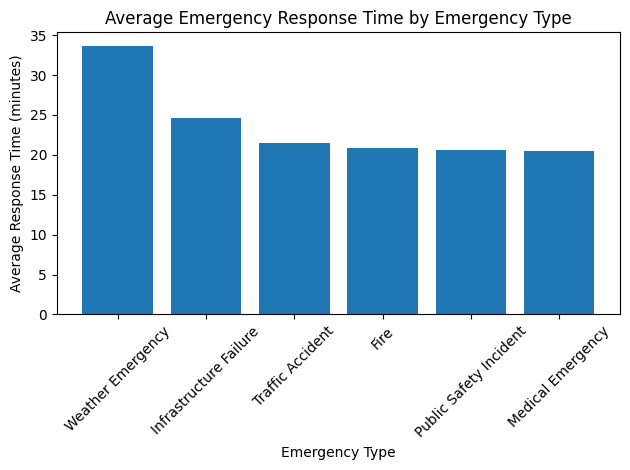

In [111]:
plt.bar(response_by_type.index, response_by_type.values)
plt.title("Average Emergency Response Time by Emergency Type")
plt.xlabel("Emergency Type")
plt.ylabel("Average Response Time (minutes)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


hour
19    1078.0
16    1068.0
8     1053.0
7     1040.0
17    1027.0
18    1027.0
9     1016.0
11     860.0
6      820.0
12     807.0
10     802.0
22     796.0
13     795.0
14     793.0
21     791.0
20     788.0
15     787.0
2      493.0
4      490.0
1      489.0
0      483.0
23     480.0
3      466.0
5      428.0
Name: accident_count, dtype: float64


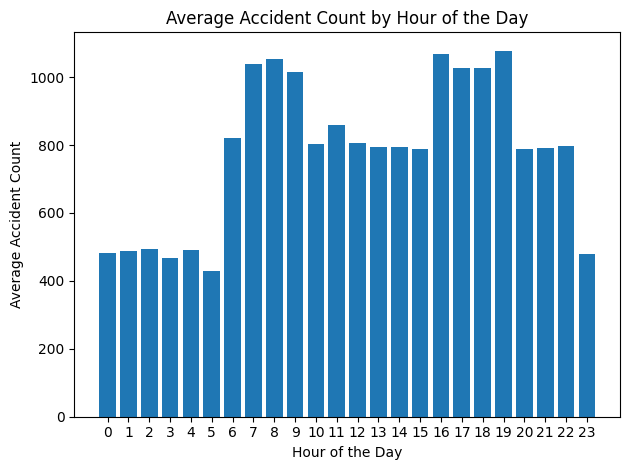

In [112]:
traffic = data["traffic"].copy()

traffic["timestamp"] = pd.to_datetime(traffic["timestamp"])

traffic["hour"] = traffic["timestamp"].dt.hour

hourly_accidents = (
    traffic
    .groupby("hour")["accident_count"]
    .sum()
).sort_values(ascending=False)

print(hourly_accidents)
plt.bar(hourly_accidents.index, hourly_accidents.values)
plt.title("Average Accident Count by Hour of the Day")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Accident Count")
plt.xticks(range(24))
plt.tight_layout()
plt.show()



### Key Insight: Accident Patterns by Hour

- Accident rates are **not evenly distributed throughout the day**.
- The highest accident rates occur during the **morning period (7–9 AM)** and the **late afternoon/evening period (4–7 PM)**.
- The **peak occurs around 7 PM**, indicating a potentially higher-risk period during the evening.
- Accident rates are noticeably lower during the **early morning hours**, particularly around **5 AM**, and again around **11 PM**.
- These patterns suggest that **time of day may be an important factor in emergency and traffic management**, especially during peak-risk hours.

<a id="presentation-conclusion"></a>


# 6. 📌 Key Insights & Conclusions

## Urban Structure

* Population is concentrated mainly in **Residential districts**, with Commercial and Industrial districts holding smaller shares.
* **Recreational districts** have the highest green-space coverage, followed by Residential districts.
* Average electricity load is moderate at approximately **61.6%**, but observed peaks above 100% — reaching approximately **197%** — indicate potential periods of **grid stress** despite moderate average utilization.

## Traffic & Accidents

* Districts with larger populations and higher average traffic volumes tend to experience more accidents, although the relationship is not perfectly linear.
* Accident counts are higher on **weekdays** than weekends and increase during **rush hours**.
* Accidents follow a clear daily pattern, peaking during the **morning commute (7–9 AM)** and **evening period (4–7 PM)**, with the lowest rates around **5 AM**.
* Higher **special-event impact levels** are consistently associated with higher traffic congestion.
* Public transport demand, measured by passenger count, is positively associated with traffic congestion.
* Traffic congestion and average speed show a **very strong inverse relationship**, indicating that higher congestion coincides with substantially lower mobility.
* Weather shows only a **weak linear relationship** with congestion and accidents when considered in isolation, but its operational impact becomes much more significant when combined with traffic conditions.

## Air Quality

* Among the measured pollutants, **CO shows the strongest observed relationship with traffic conditions**, making it a useful indicator to consider alongside traffic monitoring.
* The observed relationships are correlational and do not establish that traffic directly causes changes in pollutant levels.

## City Events

* Expected attendance rises sharply with event impact level.
* **Extreme-impact events** average approximately **66,000 attendees**, compared with roughly **5,000–6,000** for Low/Medium-impact events.
* This disproportionate increase in attendance implies substantially higher **infrastructure, mobility, and safety requirements** for large-scale events.

## Emergency Response

* **Weather Emergencies** have the longest average response time at approximately **33.7 minutes**, while **Medical Emergencies** are the fastest at approximately **20.4 minutes**.
* Response time decreases consistently as severity increases, with **Low-severity incidents averaging ≈24.8 minutes versus ≈14.7 minutes for Critical incidents**. This pattern is consistent with faster response to higher-severity incidents.
* Weather emergencies are disproportionately concentrated in **Residential districts**.
* The combination of severe weather and heavy traffic compounds response delays sharply: **Storm + High Traffic ≈42.6 minutes** versus **Clear + Low Traffic ≈12.3 minutes**, making the former more than **3× slower**.
* This highlights the importance of analyzing emergency operations together with traffic and weather conditions rather than treating each system independently.

# 7. ✅ Business Recommendations

### 1. Prioritize Emergency Readiness During Storms and Heavy Traffic

Storm conditions combined with high traffic produce the **slowest response times observed in the analysis**.

**Action:** Increase emergency readiness, dynamic routing, and resource availability when severe weather coincides with high traffic conditions.

### 2. Strengthen Weather-Emergency Preparedness in Residential Districts

Weather emergencies are disproportionately concentrated in Residential districts.

**Action:** Prioritize emergency resources, preparedness plans, and response capacity in residential areas with higher exposure to weather-related incidents.

### 3. Focus Traffic Operations Around Peak-Risk Hours

Accident activity is highest during the **7–9 AM and 4–7 PM** periods.

**Action:** Increase traffic monitoring, incident-response staffing, and emergency readiness during these windows.

### 4. Coordinate Mobility Planning Around High-Impact Events

Extreme-impact events can attract approximately **66,000 attendees**, while public transport demand is positively associated with congestion.

**Action:** Coordinate public-transit capacity, traffic management, and event planning ahead of major events to reduce network pressure.

### 5. Integrate Air Quality and Traffic Monitoring

CO has the strongest observed relationship with traffic conditions among the measured pollutants.

**Action:** Combine air-quality monitoring with traffic data to identify areas experiencing simultaneous mobility and environmental pressure.

### 6. Monitor Power-Grid Peak Stress

Average electricity utilization is moderate, but observed load peaks exceed 100%.

**Action:** Strengthen peak-demand monitoring and load-balancing mechanisms, particularly as demand grows in higher-consumption Commercial and Industrial districts.

# 8. ⚠️ Analysis Limitations & Open Items

* No correlation analysis has yet been performed between `population_density` / `road_capacity_index` and emergency response time.
* Time-based patterns were examined for accidents, but outage rates, air quality, and electricity demand have not yet been analyzed by hour/day/month.
* No unified correlation heatmap has been developed across all merged datasets.
* No predictive or classification modeling has been performed on the target flags (`accident_flag`, `outage_flag`, `service_disruption_flag`, `pollution_alert_flag`).
* All relationships reported in this notebook are **descriptive or correlational**. Statistical significance and causality have not been established.


[← Previous](#presentation-insight-6)
